# What yesterday's electricity profile can tell us about tomorrow

**Question:** How much does repeating a daily profile explain a real electricity excerpt, and what changes when its period or level is wrong?


## Objectives

A seasonal reference makes a forecasting decision inspectable. For an hourly electricity series, it asks whether the reading at this time tomorrow will resemble the reading at the same phase of the previous day. That is a specific assumption about a client's routine. It is more informative than treating a low error as an unexplained success of a large model. We will inspect the recorded time axis, forecast a reserved block, and distinguish prediction error from the historical scale used to express it.

The example uses client MT_010 from the UCI electricity collection, rather than a simulated demand curve. It is a short, curated excerpt, so its performance cannot establish accuracy across customers, seasons, tariffs or operational settings. We then add an explicitly synthetic level change to this authentic excerpt. The intervention answers a mechanism question: how long does a daily-copy rule keep using observations from the previous regime? It is not an additional observed event in the customer's record.

By the end, you should be able to compute the first forecast by looking at one earlier value, explain why a prediction band is wider at later leads, and identify which observations each score uses. You should also be able to replace the CSV with your own regularly sampled series without changing the meaning of the error denominator. These are the foundations for interpreting the more elaborate methods elsewhere in ChronoScope.


## Setup

The lesson calls the published PreqTS 0.3.0 API. Install these exact direct dependencies in the repository's isolated notebook environment before opening the notebook. Execution never installs packages.

```text
pip install numpy==2.4.6
pip install matplotlib==3.10.8
pip install preqts==0.3.0
```

NumPy supplies arrays, Matplotlib supplies figures, and PreqTS supplies the actual forecasting and prequential evaluation implementation. We do not copy a forecaster into a teaching cell. This package's empirical residual intervals differ from the Gaussian residual intervals in ChronoScope's separate lightweight atlas method; matching the name SeasonalNaive does not make the interval algorithms identical.


In [1]:
# Import the released API; the lesson does not install or redefine a method.
from pathlib import Path
import csv
from datetime import datetime
import importlib.metadata
import numpy as np
import matplotlib.pyplot as plt
from preqts import SeasonalNaive, Stream, run_prequential
from preqts.metrics import seasonal_naive_mae
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "VERSION").is_file())
plt.rcParams.update({"figure.figsize": (9, 3), "figure.dpi": 95, "font.size": 10})
for package in ("numpy", "matplotlib", "preqts"):
    print(package, importlib.metadata.version(package))
words = {'cut': 'Forecast origin',
 'time': 'Recorded local time',
 'value': 'Hourly sum (source readings in kW)',
 'history': 'Available history',
 'actual': 'Later observations',
 'forecast': 'Repeated daily cycle',
 'interval': 'Empirical 10–90% band',
 'period': 'Model period (hours)',
 'original': 'Original excerpt',
 'shift': 'Synthetic level shift',
 'arrival': 'Arrivals after intervention',
 'absolute': 'Absolute one-step error'}


numpy 2.4.6
matplotlib 3.10.8
preqts 0.3.0


## Data

`data/examples/electricity_sample.csv` contains an already prepared hourly excerpt. `unique_id` identifies the client, `ds` records local time, and `y` is the sum of four consecutive quarter-hour readings. The UCI source describes its original readings as kW and documents its daylight-saving convention. A sum of those readings is neither their hourly mean nor an energy conversion: the corresponding mean would divide the sum by four, and energy requires accounting for interval duration. We retain the committed values and label their arithmetic explicitly. The excerpt's timestamps advance hourly, including the 15-minute offset in their labels; no undocumented resampling occurs here.

Only one client is present. The final 48 observations are withheld from fitting the block forecast; the preceding values form its history. Separately, the first 96 observations define the fixed evaluation scale for the sensitivity experiment. Checking finiteness and consecutive timestamps protects the interpretation of a period of 24 as one day. A missing hour would turn a 24-row lag into a different elapsed-time comparison.


In [2]:
# Read the authentic hourly excerpt and inspect its time axis before forecasting.
with (root / "data/examples/electricity_sample.csv").open(encoding="utf-8", newline="") as file:
    rows = list(csv.DictReader(file))
times = [datetime.fromisoformat(r["ds"]) for r in rows]
y = np.array([float(r["y"]) for r in rows])
assert {r["unique_id"] for r in rows} == {"MT_010"}
assert np.isfinite(y).all()
assert all((b-a).total_seconds() == 3600 for a, b in zip(times, times[1:]))
m, warmup, horizon = 24, 96, 48
cut = len(y) - horizon
history, actual = y[:cut], y[cut:]
print("rows / prefix / held out:", len(y), len(history), len(actual))
print("first / last:", times[0].isoformat(), times[-1].isoformat())


rows / prefix / held out: 480 432 48
first / last: 2012-01-01T00:15:00 2012-01-20T23:15:00


The first figure displays the whole excerpt and marks the reserved block. Its purpose is to reveal the scale, recurring profile and any visible discontinuity before we interpret a score. The line after the origin is visible for explanation, but it is not an argument to `start`. Seeing the future in a teaching plot does not authorize using it to choose a model. The period sweep below is therefore reported as a descriptive comparison on this excerpt, not as an unbiased estimate for the best period selected from it.


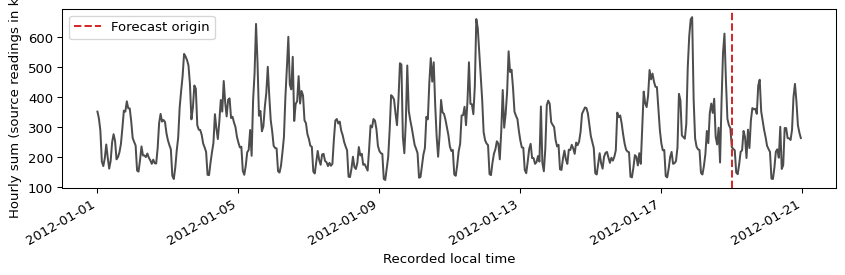

In [3]:
# Keep the reserved final block visible without passing it into the fit.
fig, ax = plt.subplots()
ax.plot(times, y, color="0.3")
ax.axvline(times[cut], color="tab:red", linestyle="--", label=words["cut"])
ax.set(xlabel=words["time"], ylabel=words["value"])
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


## Method

### Copy the last observed daily cycle

Let the available values be indexed from zero through T−1, let m be the number of readings per cycle, and let j count future leads from zero. The seasonal-copy point path is

$$
\widehat y_{T+j}=y_{T-m+(j\bmod m)},\qquad j=0,\ldots,H-1.
$$

Here T is the prefix length, H the requested horizon, and the remainder operation wraps the forecast around the final observed cycle. With m=24 and H=48, tomorrow and the following day repeat the same last day. No new trend or weekend effect appears unless it is already represented in that repeated profile. A sufficiently long history is a precondition of this interpretation: the package falls back to a one-step naive path when the available history is shorter than the requested cycle.

We first initialize a new object with the available prefix. Requesting probabilities 0.1, 0.5 and 0.9 returns an H-by-three array whose columns retain that order. The median column is exactly the copied point path. The printed first row makes the interface concrete, while the comparison with `history[-24]` supplies an independent, hand-readable value. It checks one consequence of the formula without replacing the package implementation with a second forecast algorithm.


In [4]:
# Start from the prefix, then request all three quantile columns together.
model = SeasonalNaive(seasonality=m, widen=True)
model.start(history)
q = model.predict(horizon, [0.1, 0.5, 0.9])
assert q.shape == (horizon, 3) and np.isfinite(q).all()
assert (np.diff(q, axis=1) >= 0).all()
print("first predicted row:", np.round(q[0], 4))
print("manual first point / package median:", history[-m], q[0, 1])
assert q[0, 1] == history[-m]


first predicted row: [135.6989 234.4086 380.9678]
manual first point / package median: 234.4086 234.4086


### Read an empirical band without claiming calibration

The package forms historical seasonal residuals r_i=y_i−y_{i−m}. It takes their empirical quantiles and subtracts their empirical median, so the offset at probability 0.5 is zero. With widening enabled, its requested forecast quantile is

$$
q_{T+j}(p)=\widehat y_{T+j}+\sqrt{j+1}\,[Q_p(r)-Q_{0.5}(r)].
$$

The symbol Q_p denotes the sample quantile at probability p; r denotes the residual sample available before the forecast origin. The square-root factor is an implementation choice for widening across leads. It is not a theorem about this electricity customer's conditional distribution. Residual dependence, changes in routine and unequal variance can all make the resulting band miss its nominal 80 percent coverage. The median subtraction also means an asymmetric residual distribution can produce unequal lower and upper offsets.

The implementation stores accumulated history and recomputes residual quantiles during prediction. Its protocol supports sequential updates, but this example does not demonstrate constant-time prediction or a native recurrent forecasting architecture. This distinction matters when reading timing claims: an object with an `ingest` method is not sufficient evidence that its total per-arrival cost is independent of history length.

### Separate the error from its scale

For all sensitivity candidates we use one historical seasonal-difference scale, computed from the first W=96 observations with reference period 24:

$$
s={1\over W-m}\sum_{i=m}^{W-1}|y_i-y_{i-m}|,\qquad
\operatorname{MASE}={\operatorname{mean}|y-\widehat y|\over s}.
$$

The forecast error in the numerator uses later observations. The denominator uses only the declared warmup prefix and remains unchanged across candidates. If the prefix were perfectly periodic, s could be zero and the displayed ratio would be undefined; the lesson refuses that case instead of inserting an arbitrary small constant. A MASE below one means error below this historical scale. It does not independently prove that a method beat another forecast on the future block, nor does it express monetary cost.


fixed warmup scale: 73.506574
48-step MAE / MASE / interval coverage: 60.439075 0.822227 1.000000


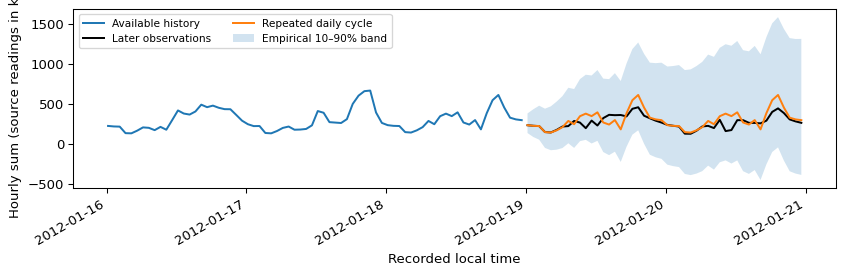

In [5]:
# Fix the historical scale once; the target is used only after prediction.
scale = seasonal_naive_mae(y[:warmup], m)
if scale <= 0:
    raise ValueError("The warmup seasonal error scale must be positive")
mae = float(np.mean(np.abs(actual - q[:, 1])))
coverage = float(np.mean((actual >= q[:, 0]) & (actual <= q[:, 2])))
print("fixed warmup scale:", f"{scale:.6f}")
print("48-step MAE / MASE / interval coverage:", f"{mae:.6f}", f"{mae/scale:.6f}", f"{coverage:.6f}")
fig, ax = plt.subplots()
ax.plot(times[cut-72:cut], history[-72:], label=words["history"])
ax.plot(times[cut:], actual, color="black", label=words["actual"])
ax.plot(times[cut:], q[:, 1], label=words["forecast"])
ax.fill_between(times[cut:], q[:, 0], q[:, 2], alpha=.2, label=words["interval"])
ax.set(xlabel=words["time"], ylabel=words["value"])
ax.legend(ncol=2, fontsize=8)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


The second figure places the repeated profile, later observations and empirical band on common axes. Read phase alignment before reading interval width: a broad band can conceal a badly timed peak while coverage alone looks acceptable. The printed MAE remains in the excerpt's arithmetic units; MASE permits a scale-free description; coverage counts how many of the 48 targets lie between the endpoints. These are complementary quantities. At later leads the band even extends below zero: this residual construction does not enforce the physical nonnegativity of electricity readings, and its complete coverage should be read alongside that excessive width. The block forecast is issued once, so its later leads do not incorporate observations arriving inside the held-out block.

### Sensitivity to the assumed cycle

We now change the question to sequential one-step forecasting after the same warmup. At each origin the harness predicts first, scores the next value, and only then reveals it through `ingest`. Every model sees the same observations in the same order. This differs from the previous 48-step forecast: later one-step forecasts have received intervening truths. Their scores must not be presented as if they evaluated the same information set as that earlier block.

The model periods 1, 12, 24 and 48 represent persistence, a half-day copy, a daily copy and a two-day copy. Crucially, `Stream` keeps its metric seasonality at 24 for every candidate. Otherwise changing the model period would also change the MASE denominator, confounding a different prediction with a different ruler. The printed scales show whether this experimental control holds for every returned result. All four candidates forecast the same arrivals; the bar heights can therefore be compared directly within this experiment.


scales for all model periods: [73.506574, 73.506574, 73.506574, 73.506574]
period / forecasts / MASE / coverage: 1 384 0.651717 0.744792
period / forecasts / MASE / coverage: 12 384 1.972140 0.760417
period / forecasts / MASE / coverage: 24 384 0.891215 0.799479
period / forecasts / MASE / coverage: 48 384 1.102410 0.807292


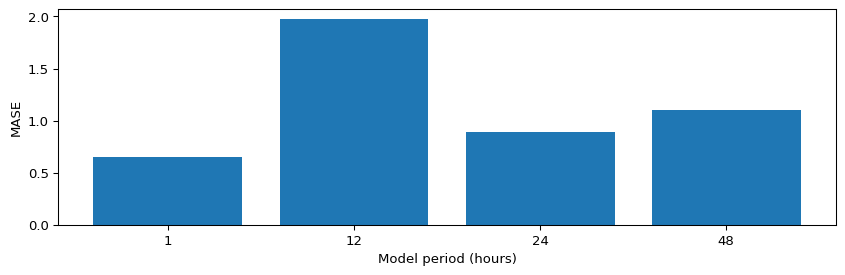

In [6]:
# Change only the model period, keeping the stream and metric period fixed.
periods = (1, 12, 24, 48)
stream = Stream(y, seasonality=m, name="MT_010-hourly-sum")
results = [run_prequential(SeasonalNaive(p), stream, horizon=1, warmup=warmup) for p in periods]
print("scales for all model periods:", [round(r.scale, 6) for r in results])
for p, r in zip(periods, results, strict=True):
    print("period / forecasts / MASE / coverage:", p, len(r.cutoffs),
          f"{np.mean(r.mase):.6f}", f"{np.mean(r.coverage):.6f}")
fig, ax = plt.subplots()
ax.bar([str(p) for p in periods], [np.mean(r.mase) for r in results])
ax.set(xlabel=words["period"], ylabel="MASE")
fig.tight_layout()
plt.show()


The third figure shows the resulting average one-step MASE by model period. A lower bar is descriptive evidence for this client and this excerpt only. The most favorable period was inspected on these outcomes, so deploying it as a selected model would require a later, untouched period for evaluation. Daily repetition can lose to persistence when adjacent hours are smoother than corresponding hours on different days. Conversely, persistence can lag behind the rising edge of a recurring daily peak. The observed ordering is something to explain from the series, not a reason to delete an inconvenient candidate.

### Limits under a change of level

To isolate adaptation delay, we add a constant equal to twice the fixed historical scale after the block origin. Both streaming models start from exactly the same unmodified history. One receives the original future; the other receives the shifted future after each prediction. During the first daily cycle, the changed model still copies values from before the intervention. Once a full cycle has arrived, both its current target and its copied reference contain the added constant, so the intervention cancels in their difference.


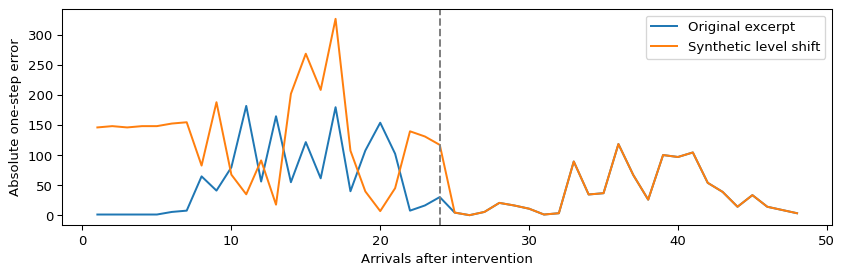

added level: 147.013147
mean absolute errors, first cycle: 61.648754 129.793906
post-cycle error-path difference: 0.00000000


In [7]:
# A declared synthetic intervention isolates the lag after a level change.
shift = 2 * scale
changed = y.copy()
changed[cut:] += shift
original_model, changed_model = SeasonalNaive(m), SeasonalNaive(m)
original_model.start(history)
changed_model.start(history)
original_errors, changed_errors = [], []
for t in range(cut, len(y)):
    original_errors.append(abs(y[t] - original_model.predict(1, [0.5])[0, 0]))
    changed_errors.append(abs(changed[t] - changed_model.predict(1, [0.5])[0, 0]))
    original_model.ingest(y[t:t+1])
    changed_model.ingest(changed[t:t+1])
fig, ax = plt.subplots()
ax.plot(np.arange(1, horizon+1), original_errors, label=words["original"])
ax.plot(np.arange(1, horizon+1), changed_errors, label=words["shift"])
ax.axvline(m, color="0.5", linestyle="--")
ax.set(xlabel=words["arrival"], ylabel=words["absolute"])
ax.legend()
fig.tight_layout()
plt.show()
print("added level:", f"{shift:.6f}")
print("mean absolute errors, first cycle:",
      f"{np.mean(original_errors[:m]):.6f}", f"{np.mean(changed_errors[:m]):.6f}")
print("post-cycle error-path difference:",
      f"{np.max(np.abs(np.array(original_errors[m:])-np.array(changed_errors[m:]))):.8f}")


The fourth figure plots absolute errors against arrivals since the intervention. The vertical marker identifies one full daily cycle, not an estimated change point. Added level does not guarantee larger absolute error at every early arrival: it may temporarily cancel an error of the opposite sign. The post-cycle error-path difference should be zero up to numerical precision because the intervention is constant and the rule copies a lag of 24. Real changes can also affect shape, variance or timing, in which case this exact cancellation need not occur. The controlled exercise explains a boundary of the rule rather than claiming a robust drift detector.

### Use it on your own data

Prepare one finite numeric value per ordered, equally spaced timestamp. Resolve duplicates, gaps, daylight-saving treatment and any aggregation before interpreting a row lag as elapsed time. Choose m from a substantive timing hypothesis and keep enough complete cycles for residual estimation. Pass only observations available at the origin into `SeasonalNaive(...).start(prefix)`, then call `predict(H, [0.1, 0.5, 0.9])`. Check the returned shape, finiteness and quantile ordering before using it downstream.

For a streaming application, issue the prediction before calling `ingest` with newly revealed observations. Keep the observation arrival policy separate from the forecast horizon. Record the warmup prefix, the metric period, the model period and the quantile levels as distinct configuration fields. The CSV fields used here supply identity, order and values; they do not by themselves specify missingness policy, operational loss or a future covariate contract. Add those decisions explicitly when extending the application.


## Results

**Answer:** Daily copying gives a 48-step MASE of 0.822227 with every held-out value inside its band. In sequential one-step prediction, persistence has the lowest observed MASE, 0.651717, compared with 0.891215 for the daily reference. A half-day copy performs worst at 1.972140. Short-term continuity therefore explains this excerpt better at one step than insisting on a daily match. The wide long-horizon band achieves complete block coverage without establishing calibrated 80 percent coverage. After the constant level intervention, the two error paths coincide again once a full daily cycle has arrived, exactly as the lag mechanism predicts.

All reported numbers come from the executed cells. Read the fixed-origin MAE and coverage alongside the 48-step plot, and read the period bars alongside the common warmup scale. Their protocols differ, so their numerical magnitudes do not constitute a head-to-head comparison. The level-change exercise adds a known perturbation and reports its effect separately from the authentic measurements. No comparison here estimates customer-wide generalization, calibrated coverage under arbitrary drift, or savings in an electricity planning decision.


## Summary

A repeated cycle is a useful explanation when its timestamp convention, reference period and information boundary are visible. Its point path is easy to inspect, while its residual interval still needs empirical evaluation. The next seasonal-phase lesson examines a different issue: how an incomplete terminal cycle changes alignment in models with explicit seasonal states. Keep this lesson's distinction between a prediction, an arrival and an evaluation scale when comparing those more elaborate forecasts.


## References

- Trindade, ElectricityLoadDiagrams20112014, UCI dataset and source conventions: https://doi.org/10.24432/C58C86
- Hyndman and Athanasopoulos, Forecasting: Principles and Practice, seasonal references and forecast evaluation: https://otexts.com/fpp3/toolbox.html
- Hyndman and Koehler, Another look at measures of forecast accuracy: https://doi.org/10.1016/j.ijforecast.2006.03.001
- PreqTS 0.3.0, published package used for this lesson's implementation: https://pypi.org/project/preqts/0.3.0/
